# 3. Visualización de datos — base de clientes

Gráficos sobre la **base completa de clientes** (`base_datos_restaurantes_USA_v2.csv`, 30.000 clientes en 10 ciudades de EE.UU.), ya que las consignas de este avance comparan **entre ciudades**.

Dos definiciones usadas en todo el notebook:
- **Gasto mensual en restaurantes** = `promedio_gasto_comida` × `frecuencia_visita` (la base trae el gasto *por comida* y las *visitas por mes*, así que el gasto mensual se deriva de ambas).
- Antes de graficar se aplica a toda la base la **misma limpieza definida en `1_EDA.ipynb`**: edades imposibles (<0 o >110) y frecuencias negativas se tratan como errores y se imputan con la mediana, igual que los nulos numéricos; las preferencias nulas se etiquetan "No especificado".

## 3.0 Preparación: carga, limpieza y estilo de los gráficos

In [1]:
import pandas as pd
import numpy as np

pd.set_option("display.max_columns", None)

df = pd.read_csv("../../Datasets/base_datos_restaurantes_USA_v2.csv", encoding="utf-8")

# Limpieza (mismas reglas que 1_EDA, aplicadas a la base completa)
df.loc[(df["edad"] < 0) | (df["edad"] > 110), "edad"] = pd.NA
df.loc[df["frecuencia_visita"] < 0, "frecuencia_visita"] = pd.NA
for col in ["edad", "frecuencia_visita", "promedio_gasto_comida"]:
    df[col] = df[col].fillna(df[col].median())
df["edad"] = df["edad"].astype(int)
df["frecuencia_visita"] = df["frecuencia_visita"].astype(int)
df["preferencias_alimenticias"] = df["preferencias_alimenticias"].fillna("No especificado")

# Variables derivadas
df["gasto_mensual"] = df["promedio_gasto_comida"] * df["frecuencia_visita"]
df["rango_edad"] = pd.cut(df["edad"], bins=[17, 30, 45, 60, 120],
                          labels=["18-30", "31-45", "46-60", "61+"])

ORDEN_ESTRATO = ["Bajo", "Medio", "Alto", "Muy Alto"]

print("Clientes:", len(df), "| Ciudades:", df["ciudad_residencia"].nunique())
print("Gasto mensual — mediana: $%.1f | media: $%.1f" % (df["gasto_mensual"].median(), df["gasto_mensual"].mean()))

Clientes: 30000 | Ciudades: 10
Gasto mensual — mediana: $102.5 | media: $173.1


In [2]:
import matplotlib as mpl
import matplotlib.pyplot as plt

# Estilo: superficie clara, ejes recesivos, tinta para el texto (paleta validada)
SUPERFICIE, TINTA, TINTA2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRILLA, EJE = "#e1e0d9", "#c3c2b7"
AZUL, NARANJA = "#2a78d6", "#eb6834"
CATEGORICO = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6"]
RAMPA_ESTRATO = {"Bajo": "#86b6ef", "Medio": "#3987e5", "Alto": "#1c5cab", "Muy Alto": "#0d366b"}

mpl.rcParams.update({
    "figure.facecolor": SUPERFICIE, "axes.facecolor": SUPERFICIE, "savefig.facecolor": SUPERFICIE,
    "font.family": "Segoe UI", "font.size": 10,
    "text.color": TINTA, "axes.labelcolor": TINTA2,
    "axes.edgecolor": EJE, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRILLA, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False, "figure.dpi": 110,
})

def preparar_ejes(ax, grid="y"):
    """Grilla solo en el eje de los valores, debajo de las marcas."""
    ax.set_axisbelow(True)
    ax.grid(axis="x", visible=(grid == "x"))
    ax.grid(axis="y", visible=(grid == "y"))

## 3.1 Diagramación: cantidad de personas por ciudad

Un dato por ciudad (magnitud) → **barras horizontales ordenadas** de mayor a menor, con el valor directo en cada barra.

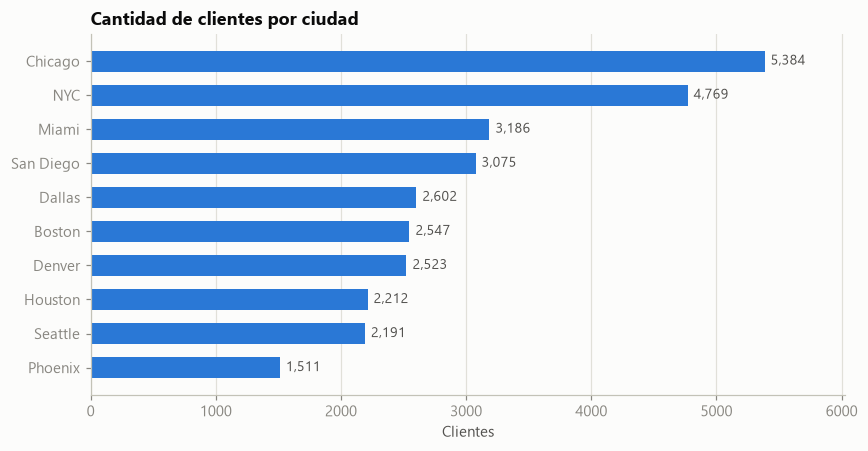

In [3]:
personas_ciudad = df["ciudad_residencia"].value_counts().sort_values()

fig, ax = plt.subplots(figsize=(8, 4.2))
preparar_ejes(ax, grid="x")
barras = ax.barh(personas_ciudad.index, personas_ciudad.values, height=0.62, color=AZUL)
ax.bar_label(barras, fmt="{:,.0f}", padding=4, color=TINTA2, fontsize=9)
ax.set_title("Cantidad de clientes por ciudad")
ax.set_xlabel("Clientes")
ax.set_xlim(0, personas_ciudad.max() * 1.12)
plt.tight_layout()
plt.show()

## 3.2 Listado: distribución por estrato socioeconómico

La consigna pide un **listado**, así que se muestra como tabla: cantidad de clientes y porcentaje por estrato, en orden de capacidad de gasto.

In [4]:
estratos = df["estrato_socioeconomico"].value_counts().reindex(ORDEN_ESTRATO).to_frame("clientes")
estratos["%"] = (estratos["clientes"] / len(df) * 100).round(1)
estratos["gasto mensual medio ($)"] = df.groupby("estrato_socioeconomico")["gasto_mensual"].mean().reindex(ORDEN_ESTRATO).round(1)
estratos

,clientes,%,gasto mensual medio ($)
estrato_socioeconomico,,,
Bajo,6161,20.5,19.1
Medio,9325,31.1,85.6
Alto,9038,30.1,188.8
Muy Alto,5476,18.3,469.8


## 3.3 Ciudades donde más se gasta en promedio al mes

Promedio del **gasto mensual** (gasto por comida × visitas al mes) por ciudad, ordenado de mayor a menor.

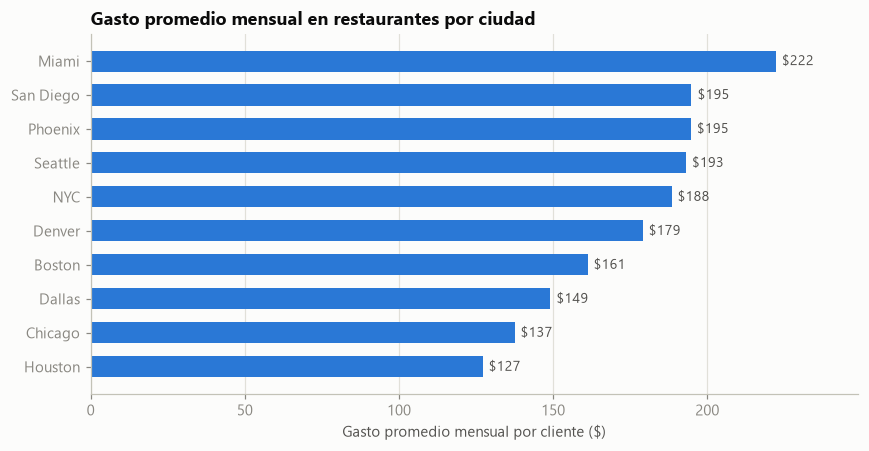

In [5]:
gasto_ciudad = df.groupby("ciudad_residencia")["gasto_mensual"].mean().sort_values()

fig, ax = plt.subplots(figsize=(8, 4.2))
preparar_ejes(ax, grid="x")
barras = ax.barh(gasto_ciudad.index, gasto_ciudad.values, height=0.62, color=AZUL)
ax.bar_label(barras, fmt="${:,.0f}", padding=4, color=TINTA2, fontsize=9)
ax.set_title("Gasto promedio mensual en restaurantes por ciudad")
ax.set_xlabel("Gasto promedio mensual por cliente ($)")
ax.set_xlim(0, gasto_ciudad.max() * 1.12)
plt.tight_layout()
plt.show()

## 3.4 Frecuencia de visita vs gasto por comida, según estrato

Para cada frecuencia de visita (0 a 10 veces/mes) se grafica el **gasto promedio por comida** de cada estrato. El estrato es una categoría *ordenada*, así que usa una rampa de un solo tono (más oscuro = mayor estrato).

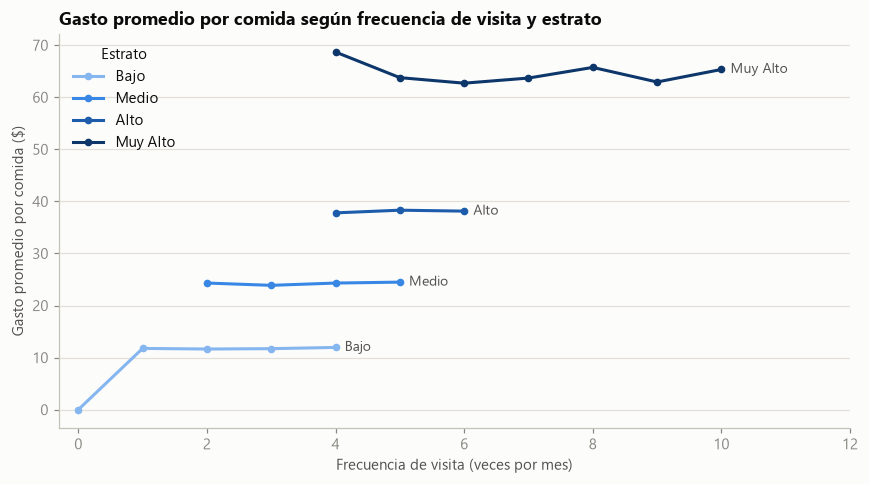

                        frecuencia_visita  promedio_gasto_comida
estrato_socioeconomico                                          
Bajo                                 1.63                   8.94
Medio                                3.52                  24.25
Alto                                 4.96                  38.06
Muy Alto                             7.31                  64.26


In [6]:
fig, ax = plt.subplots(figsize=(8, 4.5))
preparar_ejes(ax, grid="y")
for estrato in ORDEN_ESTRATO:
    sub = df[df["estrato_socioeconomico"] == estrato]
    curva = sub.groupby("frecuencia_visita")["promedio_gasto_comida"].mean()
    ax.plot(curva.index, curva.values, color=RAMPA_ESTRATO[estrato], linewidth=2,
            marker="o", markersize=4, label=estrato)
    ax.annotate(estrato, (curva.index[-1], curva.values[-1]), xytext=(6, 0),
                textcoords="offset points", va="center", fontsize=9, color=TINTA2)
ax.set_title("Gasto promedio por comida según frecuencia de visita y estrato")
ax.set_xlabel("Frecuencia de visita (veces por mes)")
ax.set_ylabel("Gasto promedio por comida ($)")
ax.set_xlim(-0.3, 12)
ax.legend(title="Estrato", loc="upper left")
plt.tight_layout()
plt.show()

print(df.groupby("estrato_socioeconomico")[["frecuencia_visita", "promedio_gasto_comida"]].mean().reindex(ORDEN_ESTRATO).round(2))

## 3.5 Dispersión: gasto mensual vs ingresos mensuales

Cada punto es un cliente (30.000). Se agrega el coeficiente de correlación para cuantificar la relación.

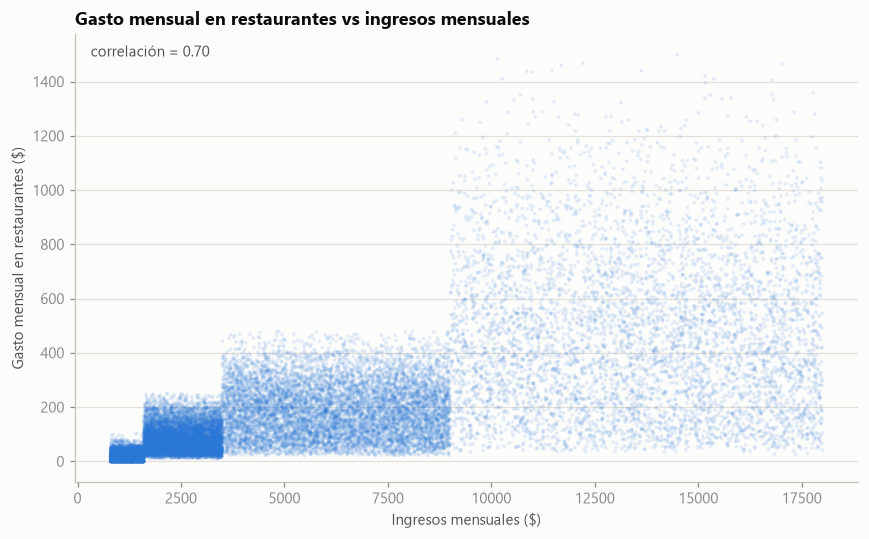

In [7]:
corr = df["ingresos_mensuales"].corr(df["gasto_mensual"])

fig, ax = plt.subplots(figsize=(8, 5))
preparar_ejes(ax, grid="y")
ax.scatter(df["ingresos_mensuales"], df["gasto_mensual"], s=6, alpha=0.12,
           color=AZUL, edgecolors="none", rasterized=True)
ax.set_title("Gasto mensual en restaurantes vs ingresos mensuales")
ax.set_xlabel("Ingresos mensuales ($)")
ax.set_ylabel("Gasto mensual en restaurantes ($)")
ax.annotate(f"correlación = {corr:.2f}", xy=(0.02, 0.95), xycoords="axes fraction",
            fontsize=10, color=TINTA2)
plt.tight_layout()
plt.show()

## 3.6 Preferencias alimenticias en todas las ciudades

Composición porcentual de preferencias por ciudad (**barras apiladas al 100%**). Cada preferencia conserva siempre el mismo color (paleta categórica validada para accesibilidad); las ciudades se ordenan por el peso de la preferencia dominante nacional.

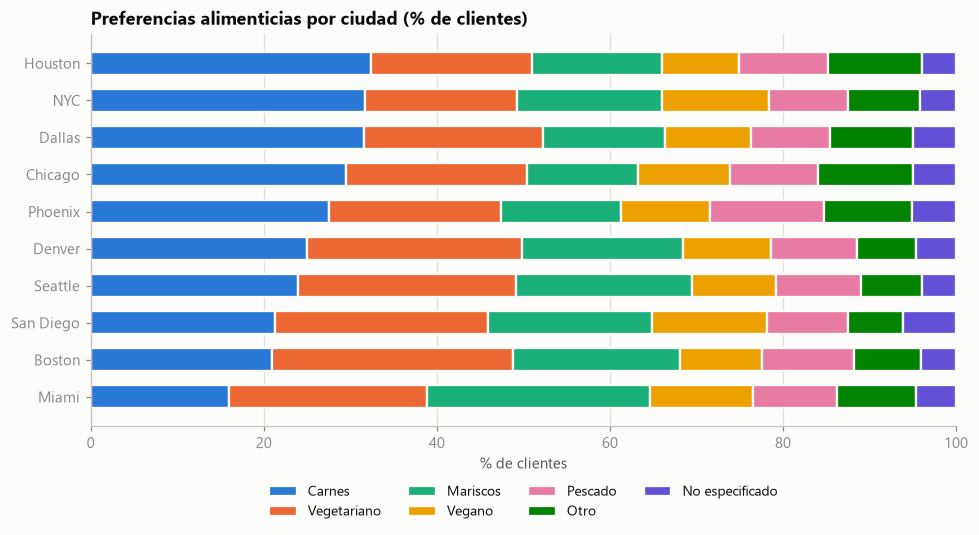

Distribución nacional (%):
preferencias_alimenticias
Carnes             26.4
Vegetariano        21.9
Mariscos           17.4
Vegano             10.9
Pescado             9.9
Otro                8.8
No especificado     4.7


In [8]:
ORDEN_PREF = ["Carnes", "Vegetariano", "Mariscos", "Vegano", "Pescado", "Otro", "No especificado"]
COLOR_PREF = dict(zip(ORDEN_PREF, CATEGORICO))

tabla_pref = (pd.crosstab(df["ciudad_residencia"], df["preferencias_alimenticias"], normalize="index") * 100)[ORDEN_PREF]
tabla_pref = tabla_pref.sort_values("Carnes")

fig, ax = plt.subplots(figsize=(9, 5))
preparar_ejes(ax, grid="x")
izquierda = np.zeros(len(tabla_pref))
for pref in ORDEN_PREF:
    ax.barh(tabla_pref.index, tabla_pref[pref], left=izquierda, height=0.62,
            color=COLOR_PREF[pref], label=pref, edgecolor=SUPERFICIE, linewidth=1.5)
    izquierda += tabla_pref[pref].values
ax.set_title("Preferencias alimenticias por ciudad (% de clientes)")
ax.set_xlabel("% de clientes")
ax.set_xlim(0, 100)
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.12), fontsize=9)
plt.tight_layout()
plt.show()

print("Distribución nacional (%):")
print((df["preferencias_alimenticias"].value_counts(normalize=True) * 100).round(1).to_string())

## 3.7 Perfil de los clientes de mayor gasto

Se define "mayor gasto" como el **10% superior por gasto mensual** (decil 10). Se compara su perfil contra el resto: qué comidas prefieren y cuánto gastan al mes.

Umbral del 10% superior: $412/mes — 3,000 clientes
Gasto mensual del grupo top — media: $678 | mediana: $625
Gasto por comida del grupo top — media: $89.0 (resto: $26.3)
Frecuencia de visita del grupo top — media: 7.7 veces/mes (resto: 3.9)

Estrato del grupo top (%):
estrato_socioeconomico
Muy Alto    94.8
Alto         5.2


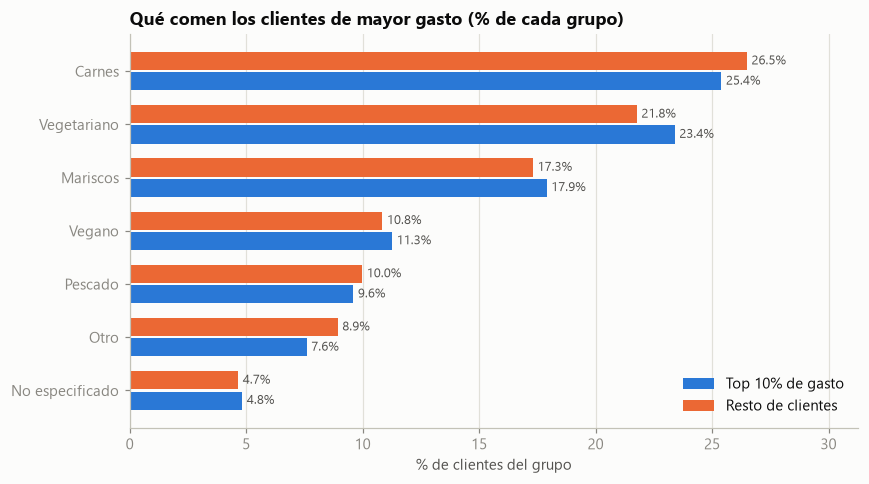

In [9]:
umbral = df["gasto_mensual"].quantile(0.90)
top = df[df["gasto_mensual"] >= umbral]
resto = df[df["gasto_mensual"] < umbral]

print(f"Umbral del 10% superior: ${umbral:,.0f}/mes — {len(top):,} clientes")
print(f"Gasto mensual del grupo top — media: ${top['gasto_mensual'].mean():,.0f} | mediana: ${top['gasto_mensual'].median():,.0f}")
print(f"Gasto por comida del grupo top — media: ${top['promedio_gasto_comida'].mean():.1f} (resto: ${resto['promedio_gasto_comida'].mean():.1f})")
print(f"Frecuencia de visita del grupo top — media: {top['frecuencia_visita'].mean():.1f} veces/mes (resto: {resto['frecuencia_visita'].mean():.1f})")
print("\nEstrato del grupo top (%):")
print((top["estrato_socioeconomico"].value_counts(normalize=True) * 100).round(1).to_string())

pref_top = (top["preferencias_alimenticias"].value_counts(normalize=True) * 100).reindex(ORDEN_PREF)
pref_resto = (resto["preferencias_alimenticias"].value_counts(normalize=True) * 100).reindex(ORDEN_PREF)

y = np.arange(len(ORDEN_PREF))
fig, ax = plt.subplots(figsize=(8, 4.5))
preparar_ejes(ax, grid="x")
b1 = ax.barh(y + 0.19, pref_top.values, height=0.34, color=AZUL, label="Top 10% de gasto")
b2 = ax.barh(y - 0.19, pref_resto.values, height=0.34, color=NARANJA, label="Resto de clientes")
ax.bar_label(b1, fmt="%.1f%%", padding=3, color=TINTA2, fontsize=8.5)
ax.bar_label(b2, fmt="%.1f%%", padding=3, color=TINTA2, fontsize=8.5)
ax.set_yticks(y, ORDEN_PREF)
ax.invert_yaxis()
ax.set_title("Qué comen los clientes de mayor gasto (% de cada grupo)")
ax.set_xlabel("% de clientes del grupo")
ax.set_xlim(0, max(pref_top.max(), pref_resto.max()) * 1.18)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 3.8 ¿En qué ciudad se pagan más membresías?

Cantidad de clientes con membresía premium por ciudad; el % sobre los clientes de cada ciudad acompaña como etiqueta (una ciudad grande puede tener más membresías en cantidad sin ser la de mayor adopción).

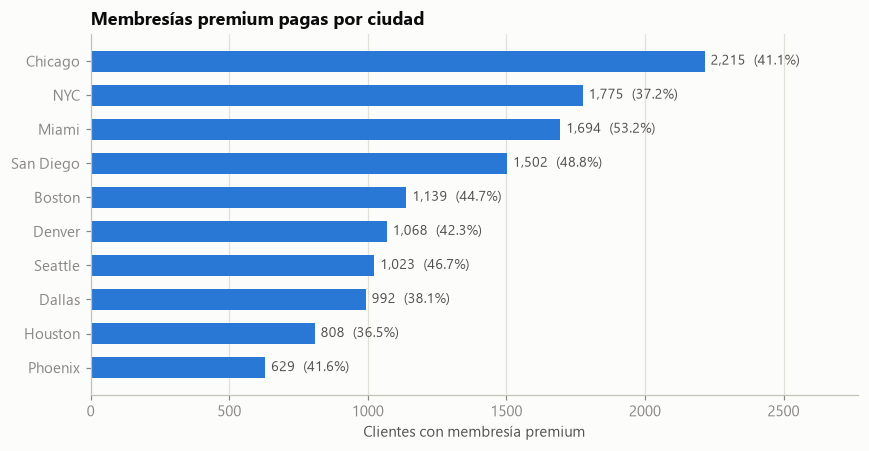

Más membresías en cantidad: Chicago (2,215)
Mayor adopción (% de sus clientes): Miami (53.2%)


In [10]:
memb = df[df["membresia_premium"] == "Sí"]["ciudad_residencia"].value_counts()
pct = (memb / df["ciudad_residencia"].value_counts() * 100).round(1)
memb = memb.sort_values()

fig, ax = plt.subplots(figsize=(8, 4.2))
preparar_ejes(ax, grid="x")
barras = ax.barh(memb.index, memb.values, height=0.62, color=AZUL)
etiquetas = [f"{v:,.0f}  ({pct[c]}%)" for c, v in memb.items()]
ax.bar_label(barras, labels=etiquetas, padding=4, color=TINTA2, fontsize=9)
ax.set_title("Membresías premium pagas por ciudad")
ax.set_xlabel("Clientes con membresía premium")
ax.set_xlim(0, memb.max() * 1.25)
plt.tight_layout()
plt.show()

print(f"Más membresías en cantidad: {memb.idxmax()} ({memb.max():,})")
print(f"Mayor adopción (% de sus clientes): {pct.idxmax()} ({pct.max()}%)")

## 3.9 Consumo de licor según la edad

Porcentaje de clientes que consume licor en cada rango etario, con la cantidad de clientes de cada rango como contexto.

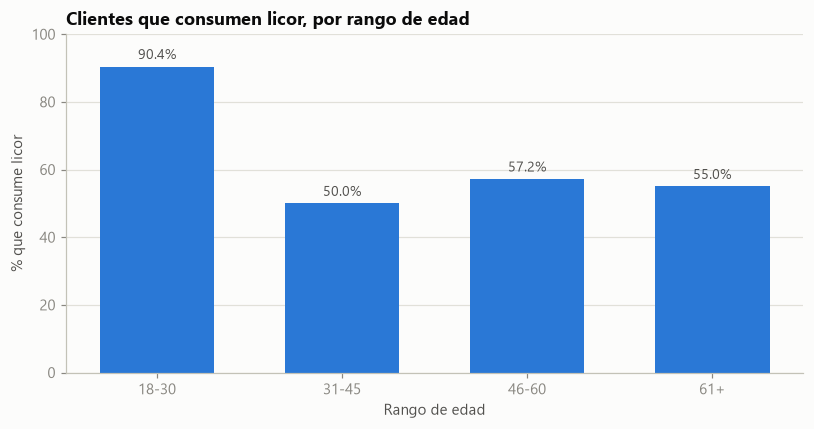

            % consume licor  clientes en el rango
rango_edad                                       
18-30                  90.4                  6149
31-45                  50.0                  7118
46-60                  57.2                  7474
61+                    55.0                  9259

Edad media — consumen licor: 46.0 | no consumen: 53.6


In [11]:
licor = (pd.crosstab(df["rango_edad"], df["consume_licor"], normalize="index") * 100)["Sí"]
clientes_rango = df["rango_edad"].value_counts().reindex(licor.index)

fig, ax = plt.subplots(figsize=(7.5, 4))
preparar_ejes(ax, grid="y")
barras = ax.bar(licor.index.astype(str), licor.values, width=0.62, color=AZUL)
ax.bar_label(barras, fmt="%.1f%%", padding=3, color=TINTA2, fontsize=9)
ax.set_title("Clientes que consumen licor, por rango de edad")
ax.set_xlabel("Rango de edad")
ax.set_ylabel("% que consume licor")
ax.set_ylim(0, 100)
plt.tight_layout()
plt.show()

resumen_licor = pd.DataFrame({"% consume licor": licor.round(1), "clientes en el rango": clientes_rango})
print(resumen_licor.to_string())
print("\nEdad media — consumen licor: %.1f | no consumen: %.1f" % (
    df.loc[df["consume_licor"] == "Sí", "edad"].mean(),
    df.loc[df["consume_licor"] == "No", "edad"].mean()))

## Conclusiones

- **Clientes por ciudad:** Chicago (5.384) y NYC (4.769) concentran la mayor cantidad de clientes; Phoenix es la menor (1.511).
- **Estratos:** la base se concentra en Medio (31,1%) y Alto (30,1%). El gasto mensual escala de forma abrupta con el estrato: de \$19/mes (Bajo) a \$470/mes (Muy Alto).
- **Dónde más se gasta al mes:** **Miami lidera con \$222 de gasto promedio mensual**, seguida de San Diego y Phoenix (\$195). Llamativo: Chicago, la ciudad con más clientes, está entre las de menor gasto medio (\$137) — volumen y ticket no van juntos.
- **Frecuencia vs gasto por comida:** ambas variables están gobernadas por el estrato. Dentro de cada estrato el gasto por comida es casi constante sin importar la frecuencia (líneas planas), pero entre estratos todo sube: el Bajo visita 1,6 veces/mes y gasta \$9 por comida, el Muy Alto visita 7,3 veces y gasta \$64.
- **Ingresos vs gasto mensual:** correlación positiva fuerte (**0,70**). Las bandas visibles en la dispersión corresponden a los estratos: los ingresos definen un techo de gasto.
- **Preferencias por ciudad:** la composición es muy pareja entre ciudades, con **Carnes** primera en casi todas (26,4% nacional) — **excepto Miami, donde domina Mariscos**, coherente con su perfil costero.
- **Clientes de mayor gasto (top 10%, ≥ \$412/mes):** gastan en promedio **\$678/mes** y son casi todos de estrato Muy Alto (94,8%). Sus gustos son prácticamente iguales a los del resto (Carnes 25,4%, Vegetariano 23,4%, Mariscos 17,9%): no comen distinto, **gastan distinto** — visitan el doble (7,7 vs 3,9 veces/mes) y pagan el triple por comida (\$89 vs \$26).
- **Membresías:** en cantidad gana **Chicago (2.215)** por su tamaño, pero la mayor adopción es de **Miami (53,2%** de sus clientes con membresía).
- **Licor y edad:** el grupo 18-30 es un caso aparte: el **90,4%** consume licor, contra 50-57% en los demás rangos. La edad media de quienes consumen (46,0) es 7,6 años menor que la de quienes no (53,6).